In [153]:
print('In the name of Allah')

In the name of Allah


In [154]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [155]:
from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

In [156]:
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.linear_model import LinearRegression,SGDRegressor
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error

# Dataset: kaggle.com/datasets/yasserh/housing-prices-dataset

#1. Basic EDA & Feature Engineering

      1. Load Housing.csv. Print .shape, .dtypes, .isnull().sum(), and .describe().
      2. Plot a histogram of price. Is it skewed?
      3. Compute .corr() on numeric columns. Which feature correlates most with price?
      4. Plot a boxplot of price grouped by stories.


In [157]:
df = pd.read_csv('Housing.csv')

df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [158]:
print('Shape : ', df.shape)
print(f'Data types :\n{df.dtypes}')

Shape :  (545, 13)
Data types :
price                int64
area                 int64
bedrooms             int64
bathrooms            int64
stories              int64
mainroad            object
guestroom           object
basement            object
hotwaterheating     object
airconditioning     object
parking              int64
prefarea            object
furnishingstatus    object
dtype: object


In [159]:
df.isnull().sum()

,0
price,0
area,0
bedrooms,0
bathrooms,0
stories,0
mainroad,0
guestroom,0
basement,0
hotwaterheating,0
airconditioning,0


In [160]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


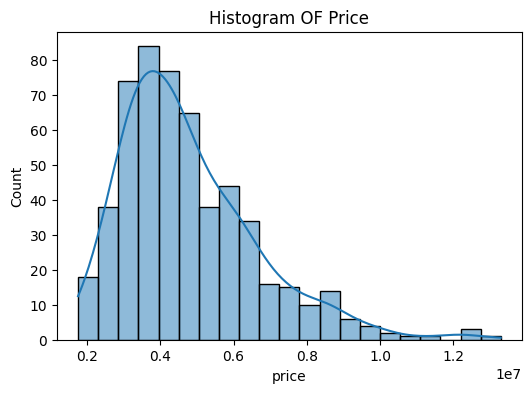

In [161]:
plt.figure(figsize = (6, 4))

sns.histplot(
    data = df,
    x = 'price',
    kde = True
)

plt.title('Histogram OF Price')
plt.show()

In [162]:
df['price'].skew()

np.float64(1.2122388370279802)

The price column is skewed

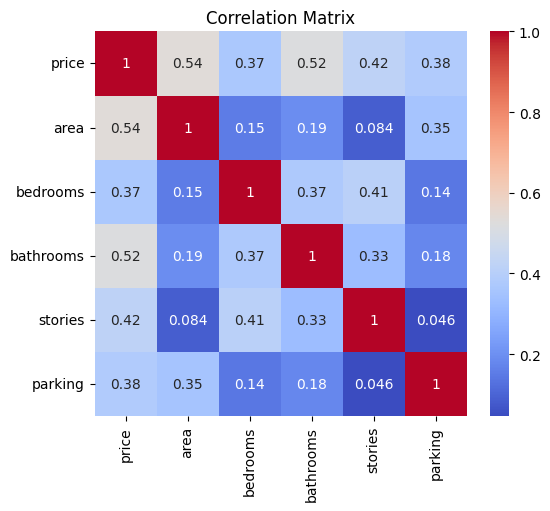

In [163]:
# cor-relation heatmap

plt.figure(figsize = (6, 5))

sns.heatmap(
    df.select_dtypes(include = np.number).corr(),
    annot = True,
    cmap = 'coolwarm'
)

plt.title('Correlation Matrix')
plt.show()


The area column correlates most with the price column

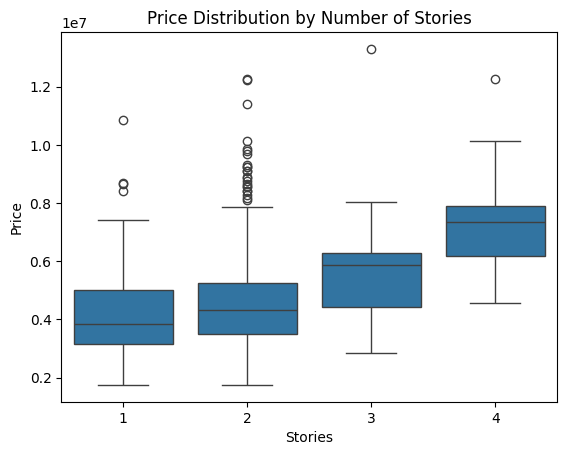

In [164]:
sns.boxplot(
    data=df,
    x='stories',
    y='price'
)

plt.xlabel('Stories')
plt.ylabel('Price')
plt.title('Price Distribution by Number of Stories')
plt.show()

# 2. Feature Engineering via Pipeline & ColumnTransformer

1. Split data: X = all features, y = price. Use train_test_split.
2. List your numeric columns in a variable called numeric_features.
3. Build a numeric_pipeline: steps = [SimpleImputer(median), StandardScaler()].
4. Wrap it in ColumnTransformer(transformers=[('num', numeric_pipeline, numeric_features)]).
5. Call preprocessor.fit_transform(X_train) and .transform(X_test). Print the output shape.


In [165]:
X = df.drop(columns = ['price'])

y = df['price']

In [166]:
X_train, X_test, y_train, y_test = train_test_split(
                                    X, y, test_size = 0.2, random_state = 42
                                    )

In [167]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   area              545 non-null    int64 
 1   bedrooms          545 non-null    int64 
 2   bathrooms         545 non-null    int64 
 3   stories           545 non-null    int64 
 4   mainroad          545 non-null    object
 5   guestroom         545 non-null    object
 6   basement          545 non-null    object
 7   hotwaterheating   545 non-null    object
 8   airconditioning   545 non-null    object
 9   parking           545 non-null    int64 
 10  prefarea          545 non-null    object
 11  furnishingstatus  545 non-null    object
dtypes: int64(5), object(7)
memory usage: 51.2+ KB


In [168]:
numeric_feature = X.select_dtypes(
    include = ['int64', 'float64']
).columns

In [169]:
numeric_feature

Index(['area', 'bedrooms', 'bathrooms', 'stories', 'parking'], dtype='object')

In [170]:
numeric_pipeline = Pipeline(
    steps = [
        ('imputer', SimpleImputer(strategy = 'median')),
        ('scaler',StandardScaler())
    ]
)

In [171]:
numeric_pipeline

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])

In [172]:
preprocessor = ColumnTransformer(
    transformers = [
        ('num', numeric_pipeline, numeric_feature)
    ]
)

In [173]:
preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 Index(['area', 'bedrooms', 'bathrooms', 'stories', 'parking'], dtype='object'))])

In [174]:
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

In [175]:
print(f'Shape of X_train_transformed : {X_train_transformed.shape}')
print(f'Shape of X_test_transformed : {X_test_transformed.shape}')

Shape of X_train_transformed : (436, 5)
Shape of X_test_transformed : (109, 5)


# 3. Train LinearRegression & SGDRegressor (using Pipeline)

1. Build lr_pipeline = Pipeline([('preprocessor', preprocessor), ('model', LinearRegression())]).
2. Fit lr_pipeline on X_train, y_train. Print .coef_ and .intercept_.
3. Build sgd_pipeline the same way but use SGDRegressor(random_state=42).
4. Fit sgd_pipeline on X_train, y_train. Print .coef_ and .intercept_.
5. Generate predictions for both models on X_train and X_test.


In [176]:
lr_pipeline = Pipeline(
    steps = [
        ('preprocessor', preprocessor),
        ('model', LinearRegression())
    ]
)

lr_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['area', 'bedrooms', 'bathrooms', 'stories', 'parking'], dtype='object'))])),
                ('model', LinearRegression())])

In [177]:
print('Coefficients : ', lr_pipeline['model'].coef_)
print('Intercept    : ', lr_pipeline['model'].intercept_)

Coefficients :  [680058.42414123 112973.18562909 565408.61793601 424354.81176353
 288348.7726677 ]
Intercept    :  4706527.385321101


In [178]:
sgd_pipeline = Pipeline(
    steps = [
        ('preprocessor', preprocessor),
        ('model', SGDRegressor(
            random_state = 42
        ))
    ]
)

sgd_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['area', 'bedrooms', 'bathrooms', 'stories', 'parking'], dtype='object'))])),
                ('model', SGDRegressor(random_state=42))])

In [179]:
print('Coefficients : ', sgd_pipeline['model'].coef_)
print('Intercept    : ', sgd_pipeline['model'].intercept_)

Coefficients :  [675359.13546814 115222.8960605  559291.60907577 419092.71035073
 287372.41478701]
Intercept    :  [4701125.93722067]


In [180]:
# Predictions
lr_train_pred  = lr_pipeline.predict(X_train)
lr_test_pred   = lr_pipeline.predict(X_test)
sgd_train_pred = sgd_pipeline.predict(X_train)
sgd_test_pred  = sgd_pipeline.predict(X_test)

# 4. Evaluation Metrics — RMSE, MAE, R²

1. Compute RMSE, MAE, R² for LinearRegression on both train and test sets.
2. Compute the same metrics for SGDRegressor.
3. Print all results in one table using a pandas DataFrame.

In [181]:
def evaluate(model, name) :

  train_pred = model.predict(X_train)
  test_pred = model.predict(X_test)

  print(f'\n{name}')
  print('-'*40)

  print("Train R2 :", round(r2_score(y_train, train_pred),4))
  print("Test R2  :", round(r2_score(y_test, test_pred),4))
  print("RMSE     :", round(np.sqrt(mean_squared_error(y_test, test_pred)),4))
  print("MAE      :", round(mean_absolute_error(y_test, test_pred),4))

  return {
        "Model"   : name,
        "Train R2": round(r2_score(y_train, train_pred), 4),
        "Test R2" : round(r2_score(y_test,  test_pred),  4),
        "RMSE"    : round(np.sqrt(mean_squared_error(y_test, test_pred)), 4),
        "MAE"     : round(mean_absolute_error(y_test, test_pred), 4)
    }

In [182]:
results = pd.DataFrame([
    evaluate(lr_pipeline, "Linear Regression"),
    evaluate(sgd_pipeline, 'SGD Regressor')
]).set_index("Model")

print('-'*40)
print(results)


Linear Regression
----------------------------------------
Train R2 : 0.5622
Test R2  : 0.5464
RMSE     : 1514173.552
MAE      : 1127483.3523

SGD Regressor
----------------------------------------
Train R2 : 0.5621
Test R2  : 0.545
RMSE     : 1516542.5289
MAE      : 1128821.241
----------------------------------------
                   Train R2  Test R2          RMSE           MAE
Model                                                           
Linear Regression    0.5622   0.5464  1.514174e+06  1.127483e+06
SGD Regressor        0.5621   0.5450  1.516543e+06  1.128821e+06


# 5. Compare Both Models

1. Which model has lower Test RMSE — LinearRegression or SGDRegressor?
2. Is Train R² much higher than Test R²?


If yes, the model may be overfitting. Learn about Overfitting and Underfitting

In [183]:
minimum_RMSE = results['RMSE'].idxmin()
print(f"Lower Test RMSE: {minimum_RMSE}")

Lower Test RMSE: Linear Regression


No — Train R2 is NOT much higher than Test R2